In [7]:
import pandas as pd

In [11]:
battles = pd.read_csv("data/battles.csv")

In [12]:
bel = pd.read_csv("data/belligerents.csv")

In [14]:
print(battles.columns.tolist())

['isqno', 'war', 'name', 'locn', 'campgn', 'postype', 'post1', 'post2', 'front', 'depth', 'time', 'aeroa', 'surpa', 'cea', 'leada', 'trnga', 'morala', 'logsa', 'momnta', 'intela', 'techa', 'inita', 'wina', 'kmda', 'crit', 'quala', 'resa', 'mobila', 'aira', 'fprepa', 'wxa', 'terra', 'leadaa', 'plana', 'surpaa', 'mana', 'logsaa', 'fortsa', 'deepa', 'is_hero', 'war2', 'war3', 'war4', 'war4_theater', 'cow_warno', 'cow_warname', 'war_initiator', 'parent', 'datetime_min', 'datetime_max', 'datetime', 'duration_days', 'duration_active_days', 'front_width_attacker', 'front_width_defender', 'latitude', 'longitude', 'coordinate_precision', 'wikidata_id', 'wikipedia_title', 'link_match', 'attacker_actors', 'defender_actors', 'attacker_str', 'defender_str', 'attacker_cas', 'defender_cas']


In [15]:
print(bel.columns.tolist())

['isqno', 'attacker', 'nam', 'co', 'str', 'code', 'intst', 'rerp', 'cas', 'finst', 'cav', 'tank', 'lt', 'mbt', 'arty', 'fly', 'ctank', 'carty', 'cfly', 'pri1', 'pri2', 'pri3', 'sec1', 'sec2', 'sec3', 'reso1', 'reso2', 'reso3', 'strpl', 'strmi', 'caspl', 'casmi', 'ach', 'actors']


In [16]:
print(battles.head())

   isqno                               war            name              locn  \
0      1  NETHERLAND'S WAR OF INDEPENDENCE        NIEUPORT  SPANISH FLANDERS   
1      2                 THIRTY YEAR'S WAR  WHITE MOUNTAIN           BOHEMIA   
2      3                 THIRTY YEAR'S WAR         WIMPFEN        PALATINATE   
3      4                 THIRTY YEAR'S WAR   DESSAU BRIDGE            ANHALT   
4      5                 THIRTY YEAR'S WAR          LUTTER         BRUNSWICK   

                               campgn  postype post1 post2  front  depth  ...  \
0                       NIEUPORT 1600        0    HD   NaN    0.0    0.0  ...   
1                        BOHEMIA 1620        1    HD    PD    1.0    0.0  ...   
2                     PALATINATE 1622        0    HD   NaN    0.0    0.0  ...   
3  DANISH INVASION OF GERMANY 1625-26        0    PD   NaN    0.0    0.0  ...   
4  DANISH INVASION OF GERMANY 1625-26        0    HD   NaN    0.0    0.0  ...   

   coordinate_precision  wikidat

Celda 1: imports y carga

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

battles = pd.read_csv("data/battles.csv")
bel = pd.read_csv("data/belligerents.csv")
print(battles.shape, bel.shape)

(660, 67) (1320, 34)


Celda 2: variable objetivo

wina
 1.0    398
-1.0    217
 0.0     43
 NaN      2
Name: count, dtype: int64


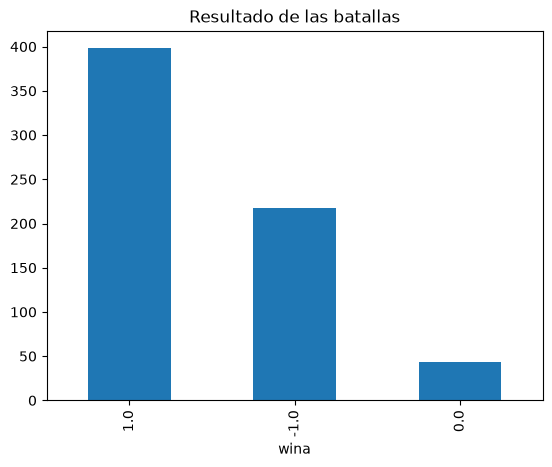

In [18]:
print(battles["wina"].value_counts(dropna=False))
battles["wina"].value_counts().plot(kind="bar", title="Resultado de las batallas")
plt.show()

Celda 3: datos faltantes

In [19]:
nulos = battles.isnull().sum().sort_values(ascending=False)
print(nulos[nulos > 0])

parent                  624
post2                   536
war4_theater            353
cow_warname             150
cow_warno               150
front                    47
time                     47
depth                    47
front_width_defender     44
plana                    35
leadaa                   35
deepa                    35
logsa                    35
momnta                   35
morala                   35
trnga                    35
leada                    35
cea                      35
aeroa                    35
terra                    35
fortsa                   35
mana                     35
wxa                      35
surpaa                   35
fprepa                   35
aira                     35
mobila                   35
logsaa                   35
inita                    35
techa                    35
quala                    35
resa                     35
intela                   35
kmda                     26
front_width_attacker     14
attacker_cas        

Celda 4: equipamiento de cada bando

In [20]:
print(bel["attacker"].unique())   # para ver cómo está codificado

equipo = ["tank", "arty", "fly"]
att = bel[bel["attacker"] == 1][["isqno"] + equipo].add_prefix("att_")
dfn = bel[bel["attacker"] == 0][["isqno"] + equipo].add_prefix("def_")

df = battles.merge(att, left_on="isqno", right_on="att_isqno", how="left") \
            .merge(dfn, left_on="isqno", right_on="def_isqno", how="left")
print(df[["name", "att_tank", "def_tank", "att_arty", "def_arty"]].head(10))

[0 1]
             name  att_tank  def_tank  att_arty  def_arty
0        NIEUPORT       0.0       0.0       8.0       6.0
1  WHITE MOUNTAIN       0.0       0.0      12.0      10.0
2         WIMPFEN       0.0       0.0       8.0      40.0
3   DESSAU BRIDGE       0.0       0.0       9.0       NaN
4          LUTTER       0.0       0.0      12.0      22.0
5   BREITENFELD I       0.0       0.0      26.0     100.0
6        THE LECH       0.0       0.0      70.0       NaN
7      ALTE VESTE       0.0       0.0       NaN       NaN
8         LUETZEN       0.0       0.0      60.0      25.0
9    NORDLINGEN I       0.0       0.0      80.0      50.0


Celda 5: año de la batalla

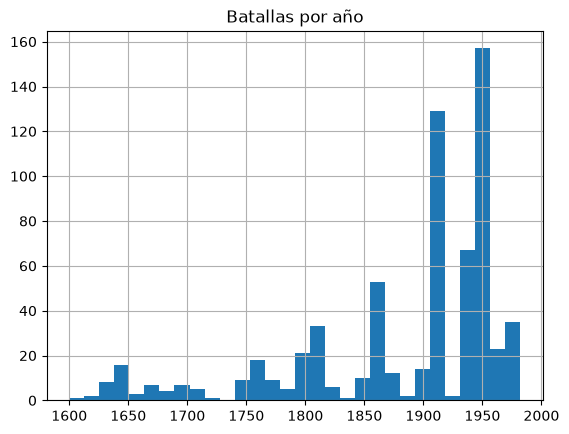

In [21]:
df["anio"] = df["datetime_min"].str[:4].astype(int)
df["anio"].hist(bins=30)
plt.title("Batallas por año")
plt.show()

Celda 6: relación de fuerzas contra resultado

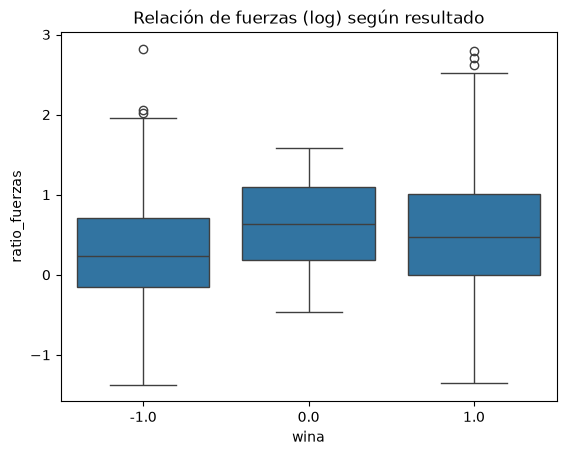

In [22]:
df["ratio_fuerzas"] = df["attacker_str"] / df["defender_str"]
sns.boxplot(x="wina", y=np.log(df["ratio_fuerzas"]), data=df)
plt.title("Relación de fuerzas (log) según resultado")
plt.show()

Celda 7: dataset final y variable objetivo

In [23]:
# Eliminar filas sin resultado o sin tropas
df = df.dropna(subset=["wina", "attacker_str", "defender_str"])

# Variable objetivo binaria
df["gana_atacante"] = (df["wina"] == 1).astype(int)
print(df["gana_atacante"].value_counts(normalize=True))

# Relación de fuerzas en logaritmo
df["log_ratio_fuerzas"] = np.log(df["attacker_str"] / df["defender_str"])
print("Infinitos:", np.isinf(df["log_ratio_fuerzas"]).sum())

gana_atacante
1    0.604262
0    0.395738
Name: proportion, dtype: float64
Infinitos: 0


Celda 8: elegir variables

In [24]:
num_cols = ["attacker_str", "defender_str", "log_ratio_fuerzas", "anio",
            "att_tank", "def_tank", "att_arty", "def_arty", "att_fly", "def_fly"]
ventaja_cols = ["aeroa", "surpa", "cea", "leada", "trnga", "morala",
                "logsa", "momnta", "intela", "techa", "inita"]
cat_cols = ["post1"]

X = df[num_cols + ventaja_cols + cat_cols]
y = df["gana_atacante"]
print(X.shape)
print(X.isnull().sum()[X.isnull().sum() > 0])

(657, 22)
att_tank     19
def_tank     20
att_arty    106
def_arty    120
att_fly     131
def_fly     139
aeroa        32
cea          32
leada        32
trnga        32
morala       32
logsa        32
momnta       32
intela       32
techa        32
inita        32
post1         1
dtype: int64


Celda 9: dividir en entrenamiento y prueba

In [25]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
print(X_train.shape, X_test.shape)

(525, 22) (132, 22)


Celda 10: pipeline de preprocesamiento

In [26]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocesador = ColumnTransformer([
    ("num", Pipeline([
        ("imputar", SimpleImputer(strategy="median")),
        ("escalar", StandardScaler())
    ]), num_cols),
    ("ventajas", SimpleImputer(strategy="constant", fill_value=0), ventaja_cols),
    ("cat", Pipeline([
        ("imputar", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), cat_cols),
])

Celda 11: línea base

In [27]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_validate

metricas = ["accuracy", "precision", "recall", "f1", "roc_auc"]

base = DummyClassifier(strategy="most_frequent")
res_base = cross_validate(base, X_train, y_train, cv=5, scoring=metricas)

Celda 12: Random Forest

In [28]:
from sklearn.ensemble import RandomForestClassifier

modelo_rf = Pipeline([
    ("prep", preprocesador),
    ("modelo", RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                      random_state=42))
])
res_rf = cross_validate(modelo_rf, X_train, y_train, cv=5, scoring=metricas)

Celda 13: Regresión Logística (alternativa)

In [29]:
from sklearn.linear_model import LogisticRegression

modelo_lr = Pipeline([
    ("prep", preprocesador),
    ("modelo", LogisticRegression(max_iter=1000, class_weight="balanced"))
])
res_lr = cross_validate(modelo_lr, X_train, y_train, cv=5, scoring=metricas)

Celda 14: tabla comparativa

In [30]:
def resumen(res):
    return {m: res[f"test_{m}"].mean() for m in metricas}

comparacion = pd.DataFrame({
    "Línea base": resumen(res_base),
    "Random Forest": resumen(res_rf),
    "Regresión Logística": resumen(res_lr),
}).T.round(3)
print(comparacion)

                     accuracy  precision  recall     f1  roc_auc
Línea base              0.604      0.604   1.000  0.753    0.500
Random Forest           0.810      0.849   0.836  0.840    0.883
Regresión Logística     0.802      0.861   0.804  0.829    0.867


Celda 15: ajuste de hiperparámetros del Random Forest

In [31]:
from sklearn.model_selection import GridSearchCV

parametros = {
    "modelo__n_estimators": [200, 500],
    "modelo__max_depth": [None, 5, 10],
    "modelo__min_samples_leaf": [1, 3, 5],
}
grid = GridSearchCV(modelo_rf, parametros, cv=5, scoring="f1", n_jobs=-1)
grid.fit(X_train, y_train)
print("Mejores parámetros:", grid.best_params_)
print("Mejor F1 (CV):", round(grid.best_score_, 3))

Mejores parámetros: {'modelo__max_depth': 10, 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 500}
Mejor F1 (CV): 0.85


Celda 16: métricas del modelo final

In [32]:
from sklearn.metrics import classification_report, accuracy_score, roc_auc_score

modelo_final = grid.best_estimator_
y_pred = modelo_final.predict(X_test)
y_proba = modelo_final.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred,
      target_names=["No gana atacante", "Gana atacante"]))
print("ROC-AUC:", round(roc_auc_score(y_test, y_proba), 3))

                  precision    recall  f1-score   support

No gana atacante       0.61      0.63      0.62        52
   Gana atacante       0.76      0.74      0.75        80

        accuracy                           0.70       132
       macro avg       0.68      0.69      0.68       132
    weighted avg       0.70      0.70      0.70       132

ROC-AUC: 0.806


Celda 17: matriz de confusión

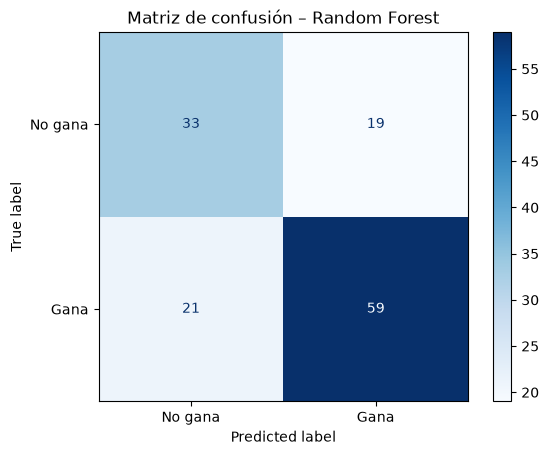

In [33]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(y_test, y_pred,
    display_labels=["No gana", "Gana"], cmap="Blues")
plt.title("Matriz de confusión – Random Forest")
plt.show()

Celda 18: curva ROC de ambos modelos

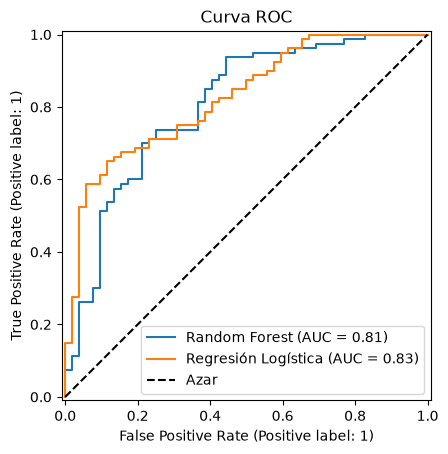

In [34]:
from sklearn.metrics import RocCurveDisplay

modelo_lr.fit(X_train, y_train)
ax = plt.gca()
RocCurveDisplay.from_estimator(modelo_final, X_test, y_test, name="Random Forest", ax=ax)
RocCurveDisplay.from_estimator(modelo_lr, X_test, y_test, name="Regresión Logística", ax=ax)
plt.plot([0, 1], [0, 1], "k--", label="Azar")
plt.legend()
plt.title("Curva ROC")
plt.show()

Celda 19: importancia de variables

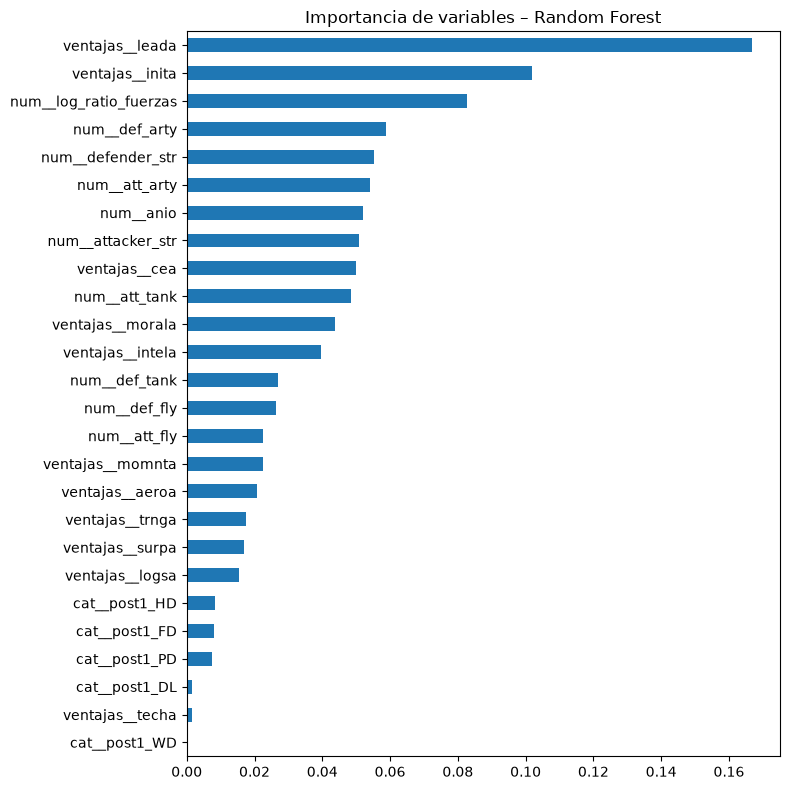

ventajas__leada           0.166724
ventajas__inita           0.101796
num__log_ratio_fuerzas    0.082796
num__def_arty             0.058925
num__defender_str         0.055136
num__att_arty             0.054117
num__anio                 0.051967
num__attacker_str         0.050727
ventajas__cea             0.050046
num__att_tank             0.048342
dtype: float64


In [35]:
nombres = modelo_final.named_steps["prep"].get_feature_names_out()
importancias = modelo_final.named_steps["modelo"].feature_importances_

imp = pd.Series(importancias, index=nombres).sort_values(ascending=True)
imp.plot(kind="barh", figsize=(8, 8))
plt.title("Importancia de variables – Random Forest")
plt.tight_layout()
plt.show()
print(imp.sort_values(ascending=False).head(10))

Celda 20: guardar el modelo

In [36]:
import joblib
joblib.dump(modelo_final, "modelo.pkl")
print("Modelo guardado")

Modelo guardado


Celda 21: reporte de la Regresión Logística

In [37]:
y_pred_lr = modelo_lr.predict(X_test)
y_proba_lr = modelo_lr.predict_proba(X_test)[:, 1]
print(classification_report(y_test, y_pred_lr,
      target_names=["No gana atacante", "Gana atacante"]))
print("ROC-AUC:", round(roc_auc_score(y_test, y_proba_lr), 3))

                  precision    recall  f1-score   support

No gana atacante       0.62      0.79      0.69        52
   Gana atacante       0.83      0.69      0.75        80

        accuracy                           0.73       132
       macro avg       0.73      0.74      0.72       132
    weighted avg       0.75      0.73      0.73       132

ROC-AUC: 0.825


Celda 22: coeficientes de la Regresión Logística

In [38]:
coefs = pd.Series(modelo_lr.named_steps["modelo"].coef_[0],
                  index=modelo_lr.named_steps["prep"].get_feature_names_out())
print(coefs.sort_values(ascending=False))

ventajas__leada           1.691104
ventajas__morala          0.956825
num__attacker_str         0.917685
ventajas__intela          0.820119
ventajas__cea             0.745516
ventajas__inita           0.732369
num__att_fly              0.656447
ventajas__momnta          0.504065
num__log_ratio_fuerzas    0.475764
num__att_tank             0.364788
ventajas__surpa           0.301612
cat__post1_WD             0.276348
ventajas__aeroa           0.251263
ventajas__logsa           0.238746
cat__post1_DL             0.214671
num__def_arty             0.133855
cat__post1_PD             0.073422
cat__post1_HD            -0.106621
num__anio                -0.107494
ventajas__techa          -0.178532
num__def_tank            -0.191562
num__att_arty            -0.199397
ventajas__trnga          -0.283036
num__def_fly             -0.366981
cat__post1_FD            -0.532097
num__defender_str        -1.148539
dtype: float64


Celda 23 guardar modelo final correcto

In [39]:
joblib.dump(modelo_lr, "modelo.pkl")
print("Modelo final guardado: Regresión Logística")

Modelo final guardado: Regresión Logística
